# Descriptive conditions in Canadian casualty collisions

## Summary

The primary 2012–2021 release contains **29,496 tractor-involved events (1,919 fatal)** and **1,065,437 events with no recorded tractor (15,109 fatal)**. Tractor events have higher recorded shares of snow, head-on and non-intersection configurations, and 00:00–05:59 clock times. These are collision composition differences, without exposure adjustment or causal interpretation.

Head-on collisions account for 6.57% of tractor casualty events but 33.40% of tractor fatal events. Their conditional fatal-event share is 641/1,939 (33.06%), compared with 271/7,572 (3.58%) for rear-end events. These are event severities, not numbers of deaths.

## Context and methods

One row per collision, selected official source releases, observed and strict sensitivity cohorts. “No recorded tractor” includes other heavy trucks and uncertain vehicle types, not just cars. All-event denominators retain unknown and valid residual other categories. Named-only shares are secondary exports. Fatal/injury strata and category-conditional fatal shares use different denominators.

### Key assumptions

Recorded type08 identifies road tractors with or without semitrailers. No property-damage-only event population is available. Clock hour is not darkness; configuration is not fault. One dictionary and valid syntax do not guarantee identical jurisdiction/year reporting. The primary period avoids the audited 1999–2000 configuration discontinuity. National event data for 2022–2025 remain unavailable to this project. Remaining benchmark differences and casualty identity uncertainty are not repaired by this descriptive analysis.

## Data and reproducible execution
The following cells regenerate all condition CSVs, figures and the full report from the immutable rebuilt collision table. No source or production event file is rewritten.

In [1]:
from pathlib import Path
import os, sys, csv, json, math
root = Path.cwd()
if not (root/'src/truck_collisions').exists():
    root = root.parent
assert (root/'data/derived/ncdb/collisions.parquet').exists()
sys.path.insert(0, str(root/'src'))
os.environ.setdefault('MPLCONFIGDIR','/tmp/collisions-matplotlib')
from truck_collisions.analyze_conditions import analyze
from truck_collisions.report_conditions import report, load, one
summary = analyze(root)
report(root)
print('Rebuilt exports:', summary['rows'])

{
  "annual_distributions": 17160,
  "period_distributions": 10296,
  "cohort_comparisons": 5148,
  "period_changes": 1716,
  "category_fatal_shares": 3432,
  "joint_distributions": 17712,
  "joint_annual_distributions": 29520
}


Rebuilt exports: {'annual_distributions': 17160, 'period_distributions': 10296, 'cohort_comparisons': 5148, 'period_changes': 1716, 'category_fatal_shares': 3432, 'joint_distributions': 17712, 'joint_annual_distributions': 29520}


## Independent direct-event validation
Recompute cohort/severity totals and every primary raw-field category count directly in DuckDB, without the analysis aggregation functions. Check all-event denominators, percentage arithmetic and conditional fatal-share formulas.

In [2]:
import duckdb
con=duckdb.connect()
event_path=str(root/'data/derived/ncdb/collisions.parquet').replace("'","''")
con.execute(f"CREATE VIEW events AS SELECT * FROM read_parquet('{event_path}') WHERE C_YEAR BETWEEN 2012 AND 2021")
totals=con.execute("SELECT is_road_tractor, count(*), count(*) FILTER(WHERE C_SEV='1') FROM events GROUP BY 1 ORDER BY 1 DESC").fetchall()
assert totals == [(True,29496,1919),(False,1065437,15109)], totals
fields=('C_WTHR','C_RSUR','C_CONF','C_RCFG','C_HOUR','C_MNTH','C_WDAY','C_RALN','C_TRAF')
period=load(root/'reports/conditions/period_distributions.csv')
checked=0
for tractor,cohort in [(True,'tractor'),(False,'no_recorded_tractor')]:
    for severity,predicate in [('all','TRUE'),('fatal',"C_SEV='1'"),('injury',"C_SEV='2'")]:
        denominator=con.execute(f'SELECT count(*) FROM events WHERE is_road_tractor={tractor} AND {predicate}').fetchone()[0]
        for field in fields:
            raw=dict(con.execute(f"SELECT coalesce({field},'<NULL>'),count(*) FROM events WHERE is_road_tractor={tractor} AND {predicate} GROUP BY 1").fetchall())
            exported=[r for r in period if r['period']=='primary_2012_2021' and r['subset']=='observed' and r['cohort']==cohort and r['severity']==severity and r['field']==field]
            assert sum(int(r['code_events']) for r in exported)==denominator
            for row in exported:
                assert int(row['code_events'])==raw.get(row['code'],0),row
                assert int(row['events'])==denominator
                assert math.isclose(float(row['share_pct']),100*int(row['code_events'])/denominator,abs_tol=1e-10)
                checked+=1
fatal=load(root/'reports/conditions/category_fatal_shares.csv')
for code,expected in [('31',(641,1939)),('21',(271,7572))]:
    row=one(fatal,period='primary_2012_2021',subset='observed',cohort='tractor',field='C_CONF',code=code)
    direct=con.execute("SELECT count(*) FILTER(WHERE C_SEV='1'),count(*) FROM events WHERE is_road_tractor AND C_CONF=?",[code]).fetchone()
    assert direct==expected==(int(row['fatal_events']),int(row['category_events']))
    assert math.isclose(float(row['fatal_share_pct']),100*direct[0]/direct[1])
print(f'Validated {checked:,} category/stratum/cohort cells plus direct conditional fatal counts.')
print('Cohort totals (tractor flag, all events, fatal events):',totals)

Validated 822 category/stratum/cohort cells plus direct conditional fatal counts.
Cohort totals (tractor flag, all events, fatal events): [(True, 29496, 1919), (False, 1065437, 15109)]


### Verify derived clock bands and a joint condition cell
The direct SQL uses hour values, not labels supplied by the aggregation module. These remain clock times, not lighting classifications.

In [3]:
for tractor,cohort in [(True,'tractor'),(False,'no_recorded_tractor')]:
    direct=con.execute(f"SELECT count(*) FROM events WHERE is_road_tractor={tractor} AND C_HOUR BETWEEN '00' AND '05'").fetchone()[0]
    row=one(period,period='primary_2012_2021',subset='observed',cohort=cohort,severity='all',field='HOUR_BAND',code='00–05')
    assert direct==int(row['code_events'])
joint=load(root/'reports/conditions/joint_distributions.csv')
row=one(joint,period='primary_2012_2021',subset='observed',cohort='tractor',severity='all',pair='weather_surface',left_code='4',right_code='5')
direct=con.execute("SELECT count(*) FROM events WHERE is_road_tractor AND C_WTHR='4' AND C_RSUR='5'").fetchone()[0]
assert direct==int(row['cell_events'])
print('Direct snow-weather/ice-surface tractor events:',direct)
con.close()

Direct snow-weather/ice-surface tractor events: 807


## Results
### Weather and surface mix
Both populations retain all events in their denominators. Unknown and Q/QQ other are distinct and visible. Rare named categories, including zeros, are retained.

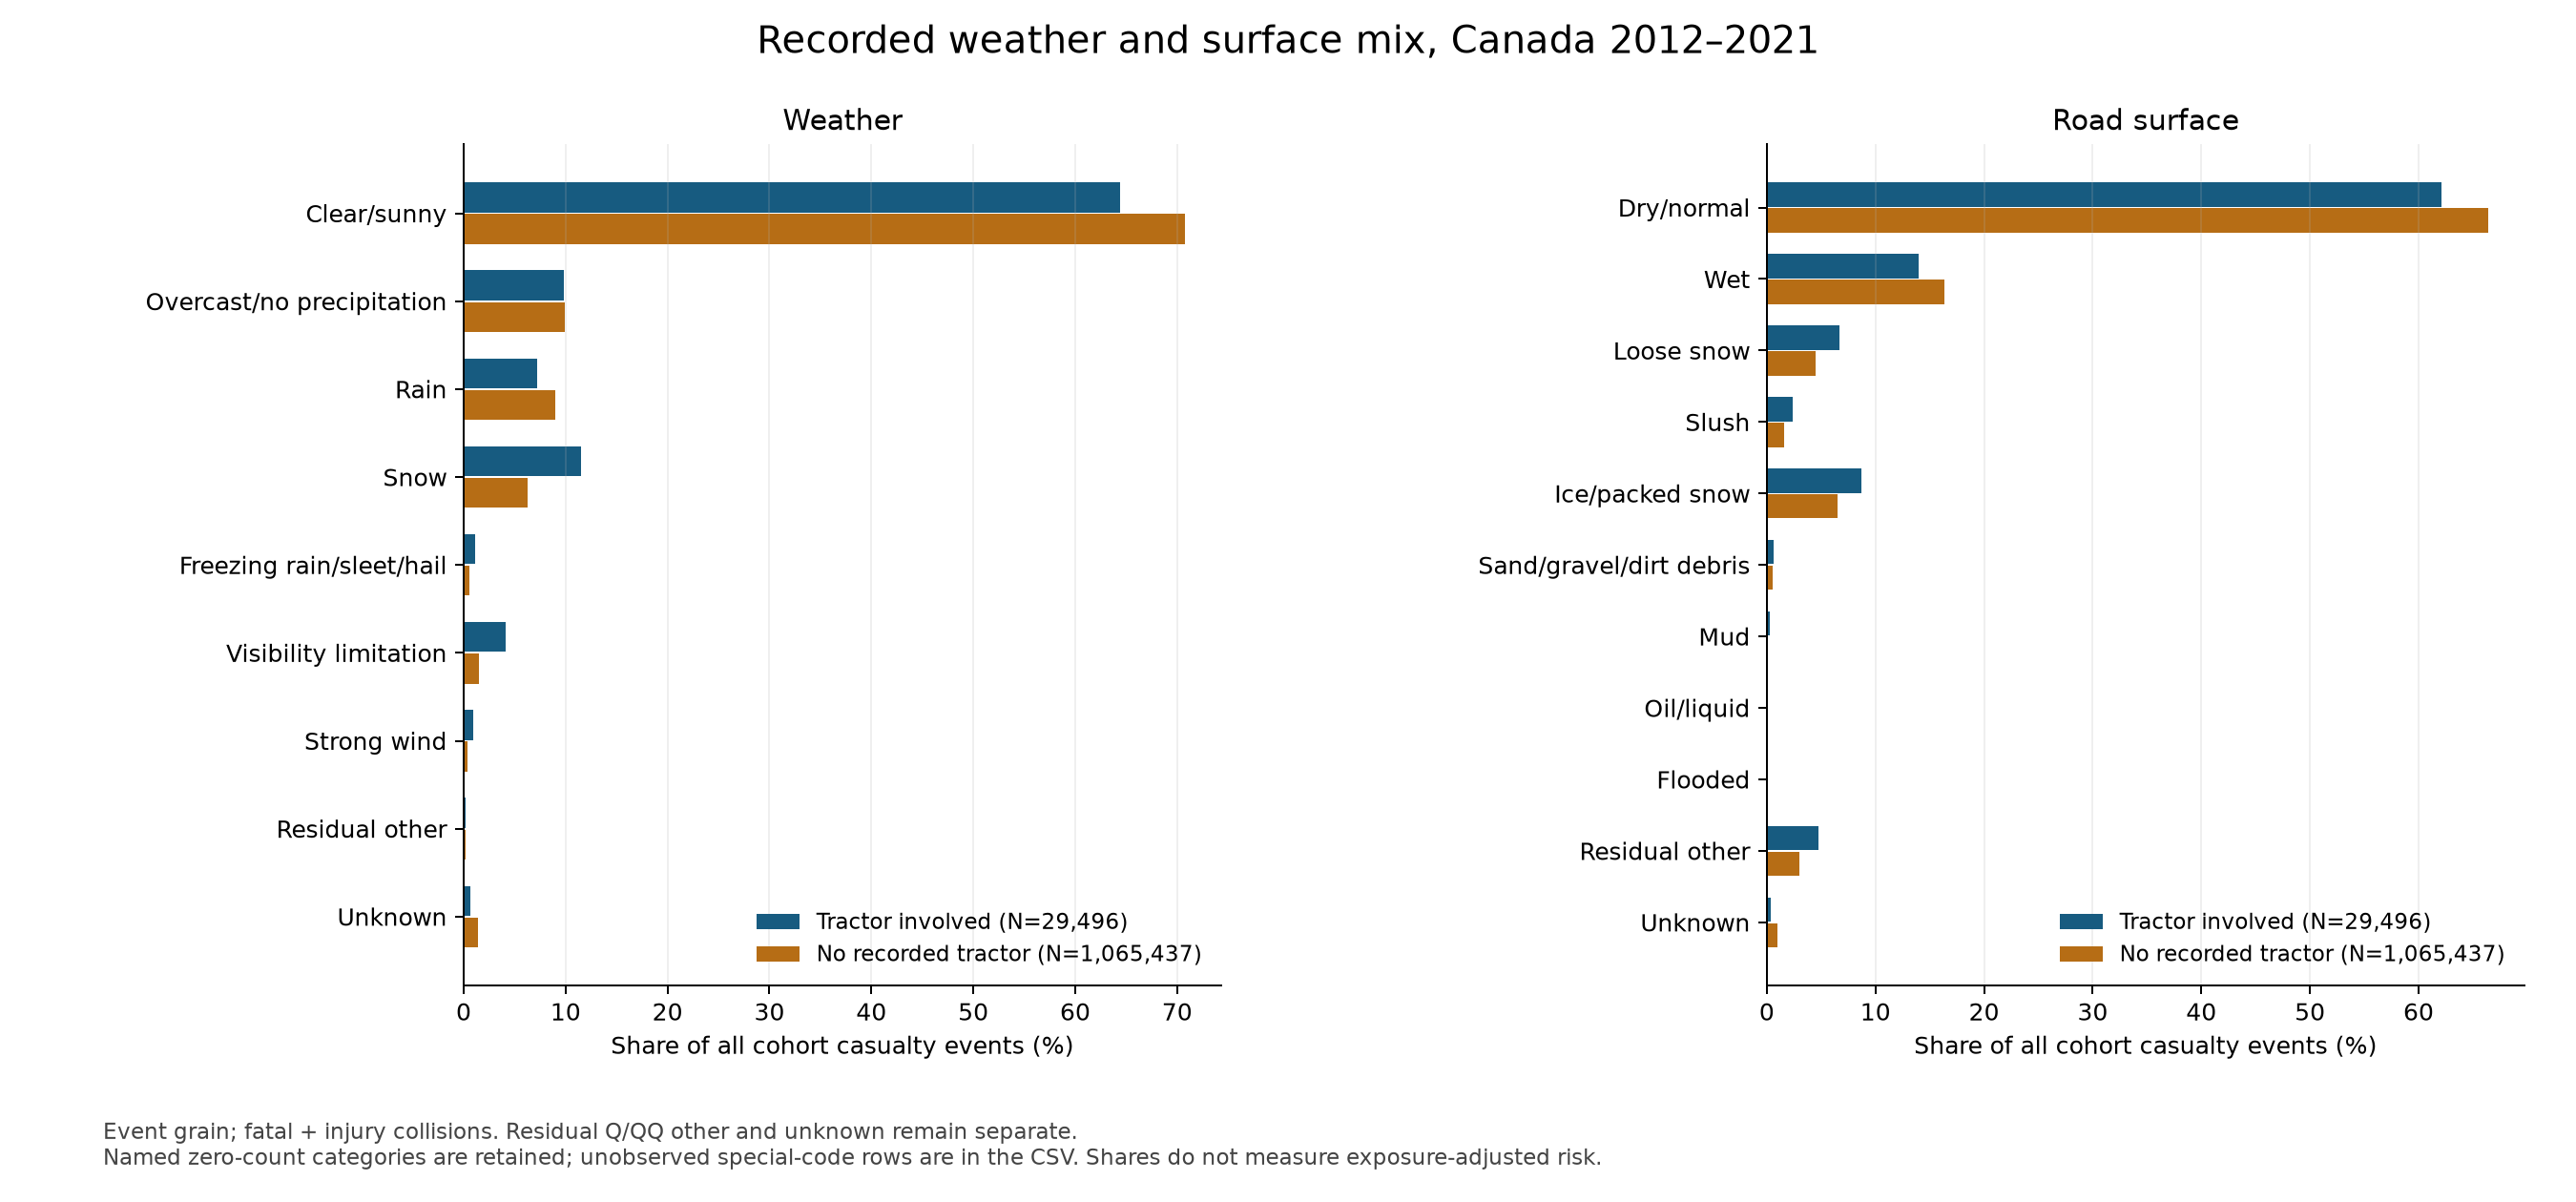

In [4]:
from IPython.display import display, Image, Markdown
display(Image(filename=str(root/'reports/conditions/pooled_weather_surface.png')))

### Annual selected shares
The lines show composition, not the number of events or exposure-adjusted rates. Complete annual tables preserve n/N, fatal/injury strata and every category, including special codes.

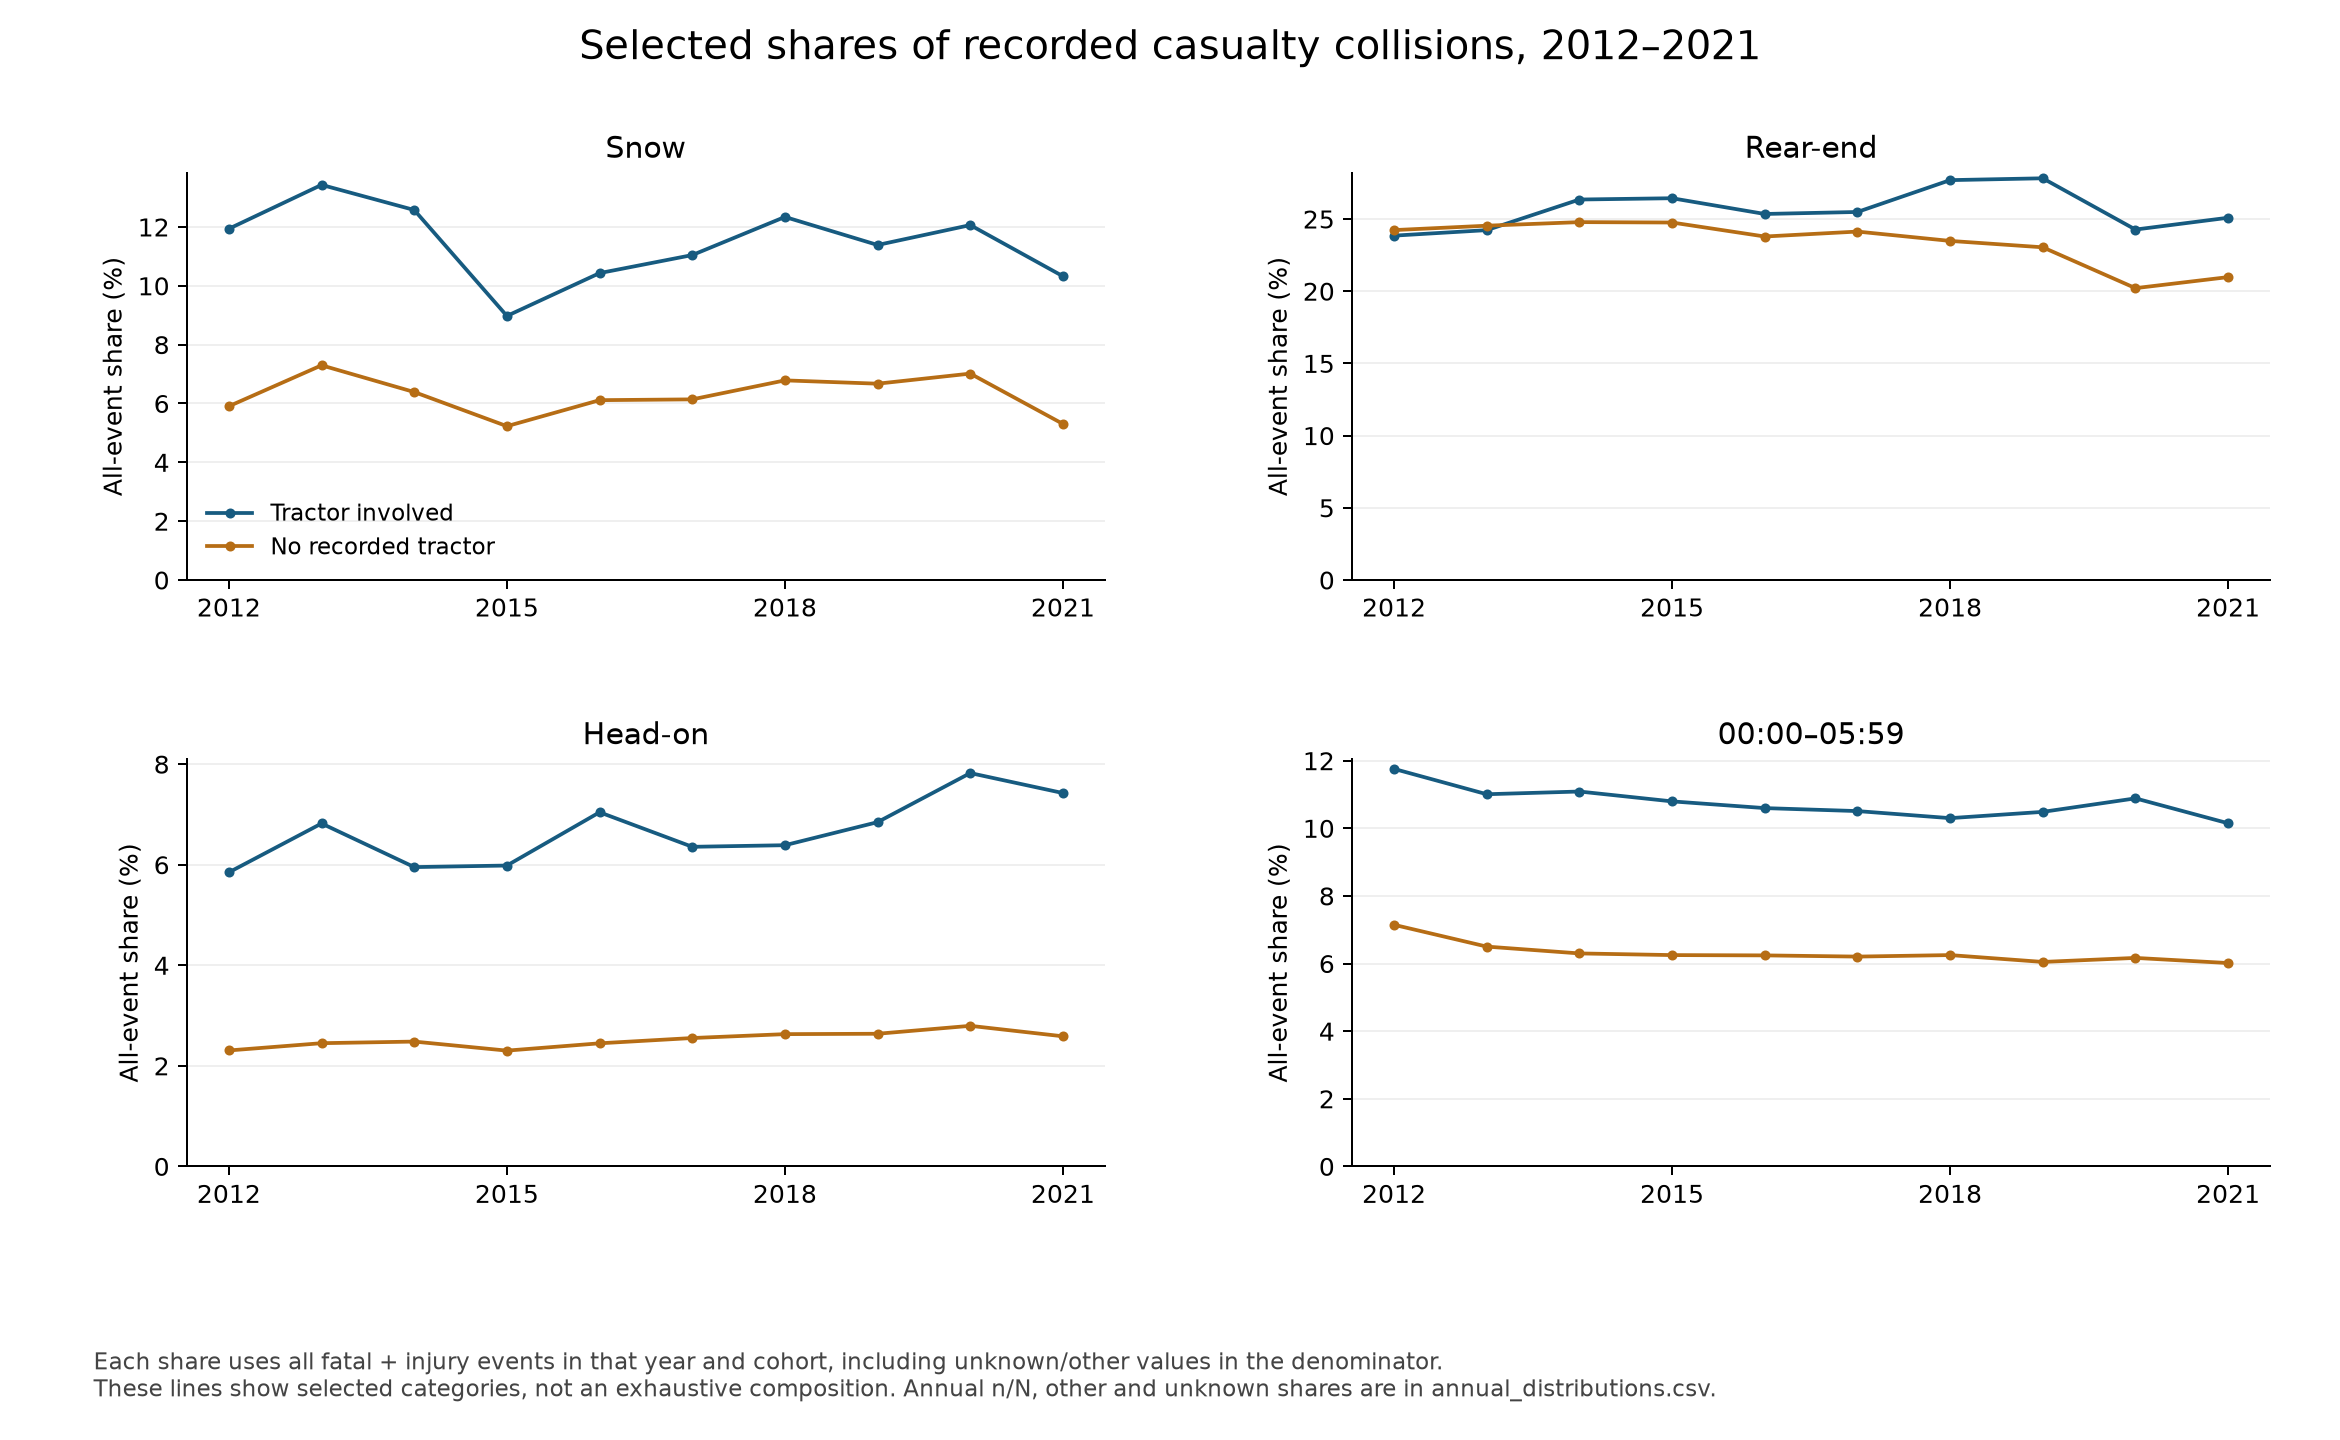

In [5]:
display(Image(filename=str(root/'reports/conditions/annual_condition_mix.png')))

### Conditional fatal-event shares
Fatal event count is divided by all fatal + injury events in that category. The n/N labels keep category size visible, particularly for sparse configurations. A fatal event may contain multiple deaths.

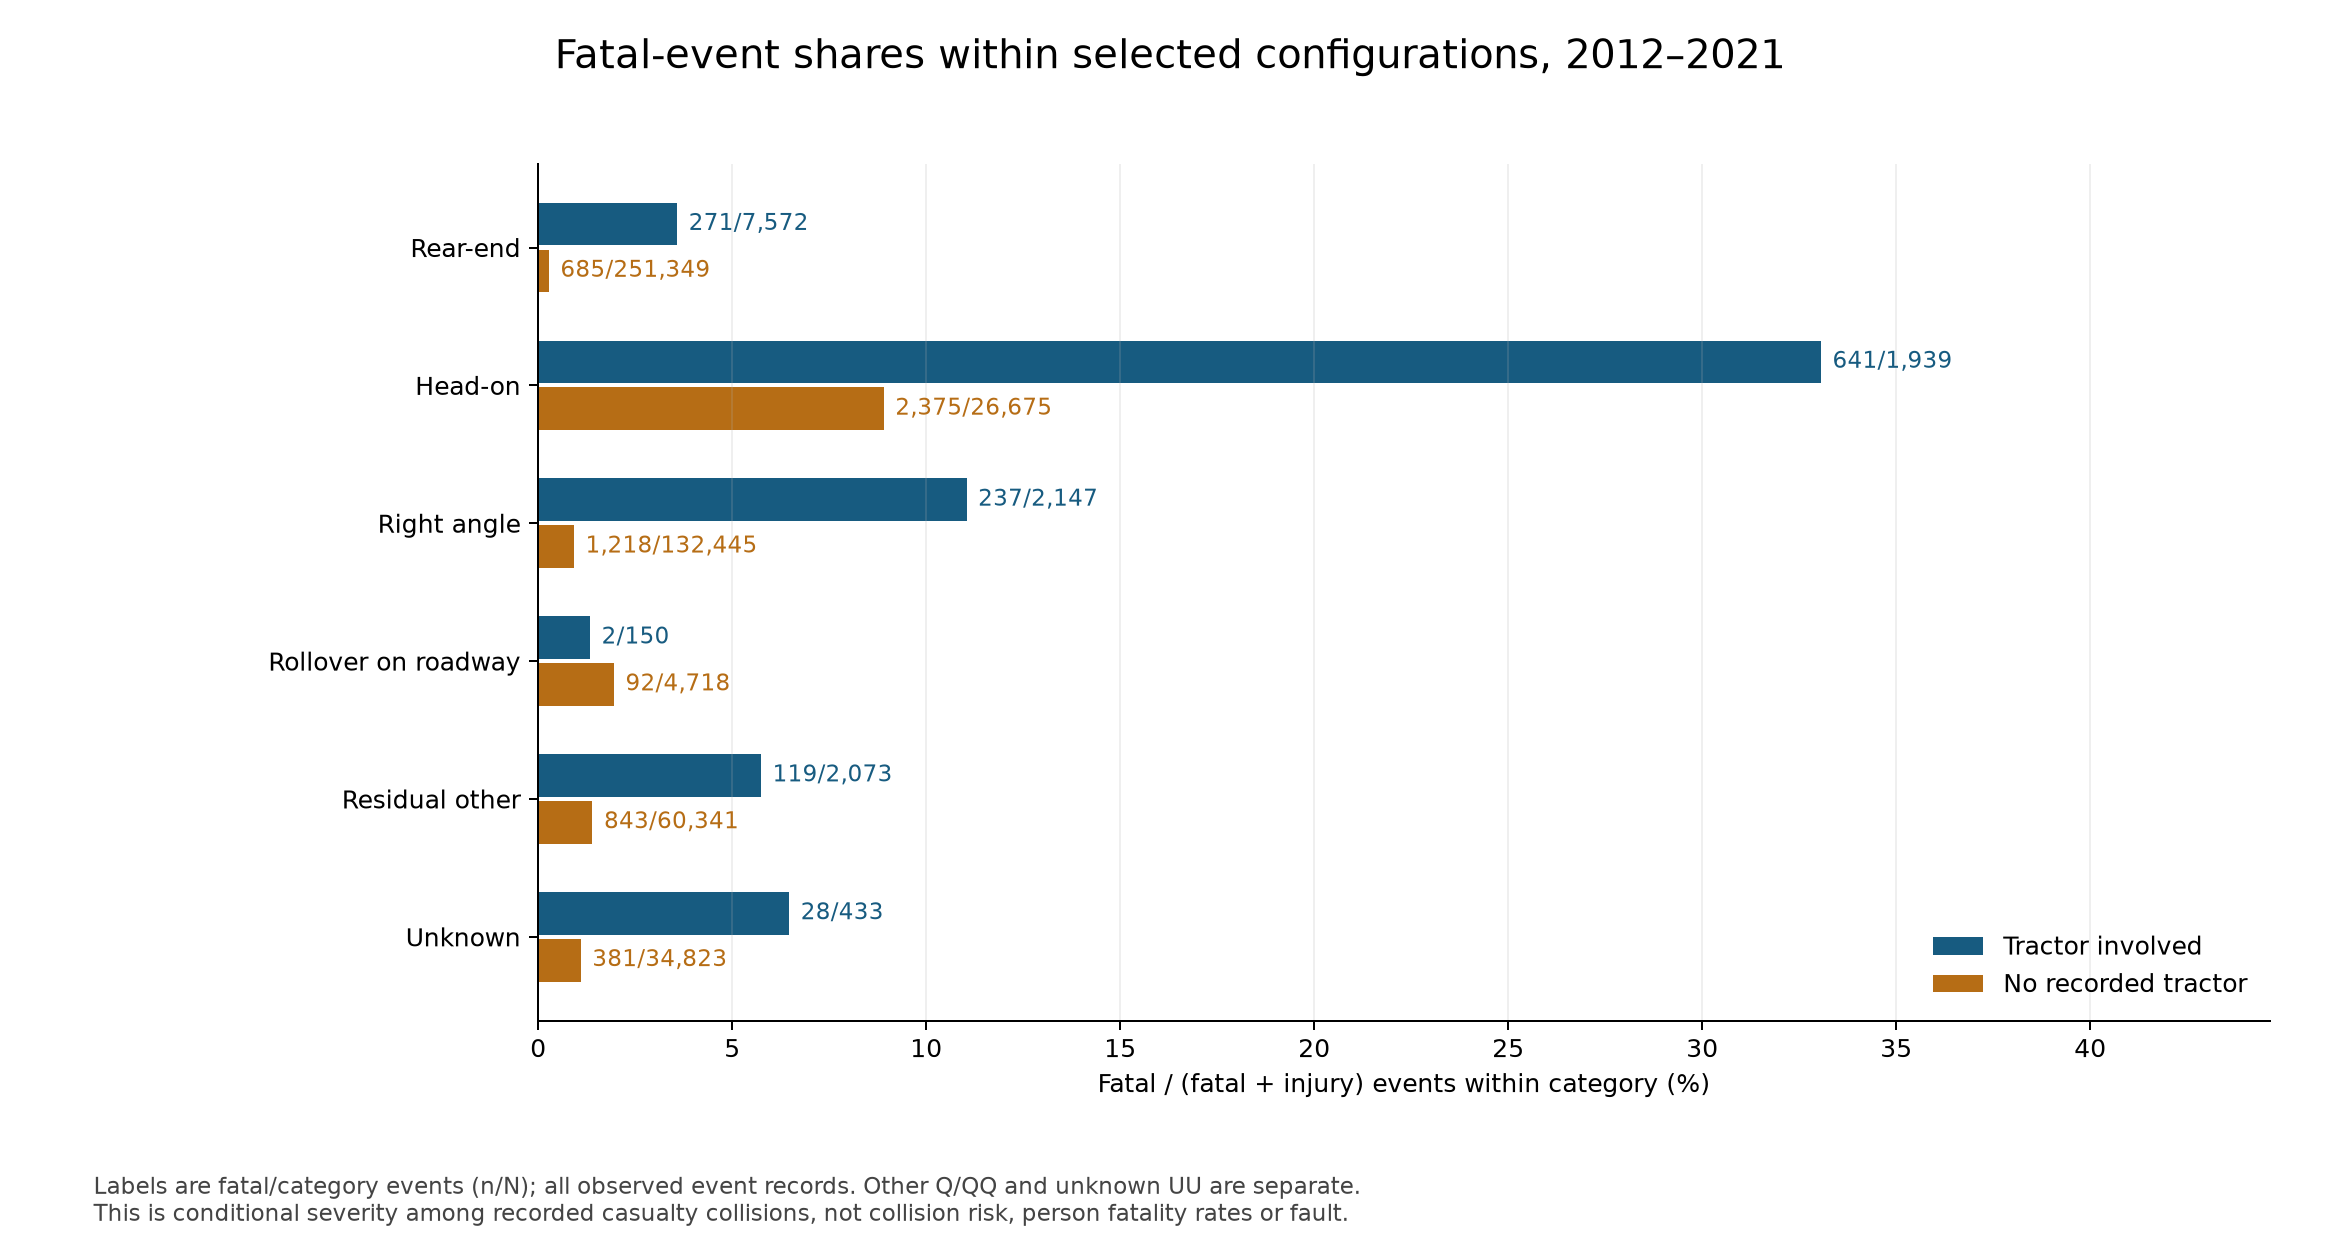

In [6]:
display(Image(filename=str(root/'reports/conditions/configuration_fatal_share.png')))

### Period and cohort tables
The full report contains every category in all nine source fields plus derived hour bands, separately for both populations and all/fatal/injury strata. It also shows early/late pooled event shares and strict, pre-2020, omit-2019 and available-2016–2021 sensitivities.

In [7]:
text=(root/'reports/conditions/findings.md').read_text()
section=text.split('## Sensitivities and cross-tabulations')[1].split('## Limits and next decision')[0]
display(Markdown('## Sensitivities and cross-tabulations'+section))

## Sensitivities and cross-tabulations

### Early versus late period

These are volume-weighted pooled event shares: summed category counts divided by summed event counts, not unweighted annual averages. Each period contains five years; the late period includes 2020–2021.

| Category | Cohort | 2012–2016 n/N (%) | 2017–2021 n/N (%) | Change (pp) |
| --- | --- | --- | --- | --- |
| Snow | Tractor involved | 1,864/16,155 (11.54%) | 1,527/13,341 (11.45%) | -0.09 |
| Snow | No recorded tractor | 36,189/584,822 (6.19%) | 30,756/480,615 (6.40%) | +0.21 |
| Rear-end | Tractor involved | 4,076/16,155 (25.23%) | 3,496/13,341 (26.20%) | +0.97 |
| Rear-end | No recorded tractor | 142,800/584,822 (24.42%) | 108,549/480,615 (22.59%) | -1.83 |
| Head-on | Tractor involved | 1,021/16,155 (6.32%) | 918/13,341 (6.88%) | +0.56 |
| Head-on | No recorded tractor | 14,017/584,822 (2.40%) | 12,658/480,615 (2.63%) | +0.24 |
| 00:00–05:59 | Tractor involved | 1,787/16,155 (11.06%) | 1,395/13,341 (10.46%) | -0.61 |
| 00:00–05:59 | No recorded tractor | 37,984/584,822 (6.49%) | 29,528/480,615 (6.14%) | -0.35 |

### Strict and alternative period windows

| Scenario | Cohort | Events | Snow n/N (%) | Head-on n/N (%) | 00:00–05:59 n/N (%) |
| --- | --- | --- | --- | --- | --- |
| Primary | Tractor involved | 29496 | 3,391/29,496 (11.50%) | 1,939/29,496 (6.57%) | 3,182/29,496 (10.79%) |
| Primary | No recorded tractor | 1065437 | 66,945/1,065,437 (6.28%) | 26,675/1,065,437 (2.50%) | 67,512/1,065,437 (6.34%) |
| Strict | Tractor involved | 29485 | 3,385/29,485 (11.48%) | 1,939/29,485 (6.58%) | 3,182/29,485 (10.79%) |
| Strict | No recorded tractor | 1065435 | 66,945/1,065,435 (6.28%) | 26,675/1,065,435 (2.50%) | 67,511/1,065,435 (6.34%) |
| 2012–2019 | Tractor involved | 25098 | 2,900/25,098 (11.55%) | 1,604/25,098 (6.39%) | 2,720/25,098 (10.84%) |
| 2012–2019 | No recorded tractor | 906255 | 57,168/906,255 (6.31%) | 22,394/906,255 (2.47%) | 57,819/906,255 (6.38%) |
| Omit 2019 | Tractor involved | 26721 | 3,075/26,721 (11.51%) | 1,749/26,721 (6.55%) | 2,891/26,721 (10.82%) |
| Omit 2019 | No recorded tractor | 963582 | 60,148/963,582 (6.24%) | 23,988/963,582 (2.49%) | 61,352/963,582 (6.37%) |
| 2016–2021 available | Tractor involved | 16351 | 1,841/16,351 (11.26%) | 1,130/16,351 (6.91%) | 1,714/16,351 (10.48%) |
| 2016–2021 available | No recorded tractor | 595926 | 37,805/595,926 (6.34%) | 15,481/595,926 (2.60%) | 36,725/595,926 (6.16%) |

For these selected contrasts, the higher tractor shares of snow, head-on and 00:00–05:59 collisions persist across the strict, pre-2020, omit-2019 and available-2016–2021 views. This is descriptive stability of composition differences, not proof that reporting or exposure confounding is absent. It does not establish identical stability for every small category.

The machine-readable tables retain observed and strict cohorts, early 2012–2016 versus late 2017–2021, pre-2020, omission of 2019, and the available 2016–2021 target-period segment. Strict excludes existing inconsistent-event/type cases and is a sensitivity, not a corrected truth. Source revisions are already applied; the selected release is fingerprinted. A source-identification check accompanies annual denominators. Sensitivity period windows answer different descriptive questions and must not be presented as interchangeable estimates.

The weather × surface and crash configuration × hour-band exports retain the full category grid, including zero and special-code cells, separately for both cohorts and all/fatal/injury strata. These are exploratory tables, not tests of interaction, causality or fault. Sparse cells retain visible counts rather than being suppressed or modelled.



## Takeaways

- Recorded tractor casualty collisions have a different condition mix from the broad no-recorded-tractor comparator; geography, travel exposure and reporting cannot be separated here.
- Higher snow, head-on and 00:00–05:59 shares persist in the selected sensitivity windows. Early/late and annual results describe different temporal contrasts.
- Head-on collisions contribute a much larger share of tractor fatal events than their share of tractor casualty events. This identifies a mechanism for further study without assigning responsibility.
- Cross-tabulations retain zero and small cells; no significance tests or causal claims are made. Multivariable complete-case selection remains inappropriate without addressing availability differences.
- Next analyses need suitable exposure or comparison designs; person-harm comparisons must preserve the casualty scenarios.

### Evidence

[Full report](../reports/conditions/findings.md) · [Run hashes and invariants](../reports/conditions/summary.json) · [Quality audit](../docs/conditions_quality.md) · [Source release repair](../docs/source_release_update.md)

Validation: this notebook regenerates results and independently validates direct event counts, denominators and selected formulas. The three figures were inspected for readable labels, scales, count annotations and separate unknown/other categories.